# Prediksi Harga Jual Mobil Bekas
---
## 1. Business Understading
### 1.1 Latar Belakang, Masalah, Solusi
1. **Latar Belakang**: Sebuah platform e-commerce otomotif global ingin membangun sistem pintar untuk mengestimasi harga wajar mobil bekas secara otomatis (*Auto-Valuation System*). Sistem ini dirancang untuk membantu pembeli dan penjual mengetahui kisaran harga pasar yang akurat berdasarkan spesifikasi fisik, usia kendaraan, riwayat servis, serta kategori kelas harga mobil tersebut.
2. **Masalah**: Platform tesebut masih mengestimasi harga jual mobil bekas secara manual. yang membuat pendapatan platform tersebut menjadi tidak maksimal.
3. **Solusi**: Membangun model *machine learning* dengan menggunakan algoritma **Multiple Linear Regressino**.

### 1.2 Deskripsi Kolom Dataset (**`automobile_dataset.csv`**)
| Nama Kolom | Tipe Data | Keterangan |
| :--- | :---: | :---: |
| **`Make`** | str | Merek atau pabrikan mobil |
| **`Model`** | str | Nama model spesifik dari kendaraan |
| **`Year`** | int64 | Tahun pembuatan mobil |
| **`Fuel_Type`** | str | Jenis bahan bakar yang digunakan kendaraan |
| **`Transmission`** | str | Jenis transmisi atau persneling mobil |
| **`Engine_Size`** | float64 | Kapasitas mesin kendaraan |
|**`Mileage`** | int64 | Jarak total yang sudah ditempuh oleh mobil |
|**`Horsepower`** | float64 | Daya kuda atau tenaga maksimal yang dihasilkan oleh mesin mobil |
|**`Torque`** | float64 | Kapasitas puntir atau tenaga putar mesin yang memengaruhi akselerasi kendaraan |
|**`Owners`** | int64 | Jumlah tangan kepemilikan sebelumnya |
|**`Accident_History`** | float64 | Catatan riwayat kecelakaan kendaraan |
|**`Service_History`** | str | Riwayat perawatan atau servis berkala mobil di bengkel resmi/umum |
|**`Color`** | str | Warna eksterior mobil |
|**`Body_Type`** | str | BJenis bodi atau bentuk fisik mobil |
|**`Drivetrain`** | str | Sistem penggerak roda kendaraan |
|**`Fuel_Efficiency`** | float64 |  |
|**`Location`** | str | Wilayah atau lokasi geografis tempat kendaraan tersebut dijual/didaftarkan |
|**`Selling_Price`** | int64 | Harga jual mobil bekas |

---

## 2. Data Preparation

### 2.1 Import Library

In [60]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load Dataset

In [61]:
df = pd.read_csv('automobile_dataset.csv')
df.columns = df.columns.str.strip()

### 2.3 Tampilkan Data Teratas dan Terbawah

In [62]:
df.head()

,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,NaN,Silver,SUV,AWD,30.0,IL,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,0.0,NaN,Blue,SUV,FWD,35.0,FL,500
2,Volkswagen,Golf,2021,Hybrid,NaN,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429
3,Chevrolet,Tahoe,2005,Petrol,NaN,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,NaN,FL,2199
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792


In [63]:
df.tail()

,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price
5495,Volkswagen,Tiguan,2022,Petrol,Automatic,NaN,29506,161.0,NaN,1,0.0,Partial Service,Black,SUV,AWD,33.0,GA,20333
5496,Nissan,Pathfinder,2006,Petrol,Automatic,3.1,287332,243.0,227.0,5,1.0,No Service,Gray,SUV,AWD,NaN,NY,500
5497,BMW,X3,2013,Petrol,Automatic,2.2,95961,171.0,152.0,2,1.0,No Service,Blue,SUV,AWD,32.0,MI,9882
5498,Volkswagen,Golf,2020,Hybrid,Automatic,1.5,56643,135.0,125.0,2,1.0,No Service,White,Hatchback,FWD,57.0,NY,10474
5499,Chevrolet,Tahoe,2011,Petrol,Automatic,2.1,169929,168.0,158.0,3,1.0,NaN,Gray,SUV,AWD,NaN,MI,6193


### 2.4 Tampilkan Informasi Data

In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Make              5500 non-null   str    
 1   Model             5500 non-null   str    
 2   Year              5500 non-null   int64  
 3   Fuel_Type         5500 non-null   str    
 4   Transmission      4673 non-null   str    
 5   Engine_Size       4656 non-null   float64
 6   Mileage           5500 non-null   int64  
 7   Horsepower        4700 non-null   float64
 8   Torque            4701 non-null   float64
 9   Owners            5500 non-null   int64  
 10  Accident_History  4688 non-null   float64
 11  Service_History   4645 non-null   str    
 12  Color             4697 non-null   str    
 13  Body_Type         5500 non-null   str    
 14  Drivetrain        5500 non-null   str    
 15  Fuel_Efficiency   4706 non-null   float64
 16  Location          4718 non-null   str    
 17  Sellin

### 2.5 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Duplikat

In [65]:
print(f'Dimensi Data: {df.shape}')
print(f'Jumlah Data: {df.size}')

print('\nJumlah Missing Value: ', df.isnull().sum().sum())
print(f'==== Missing Value Setiap Kolom ====')
print(df.isnull().sum())

print('\nJumlah Data Duplikat: ', df.duplicated().sum())

Dimensi Data: (5500, 18)
Jumlah Data: 99000

Jumlah Missing Value:  7316
==== Missing Value Setiap Kolom ====
Make                  0
Model                 0
Year                  0
Fuel_Type             0
Transmission        827
Engine_Size         844
Mileage               0
Horsepower          800
Torque              799
Owners                0
Accident_History    812
Service_History     855
Color               803
Body_Type             0
Drivetrain            0
Fuel_Efficiency     794
Location            782
Selling_Price         0
dtype: int64

Jumlah Data Duplikat:  0


---

## 3. Exploratory Data Analysis (EDA)

### 3.1 Tampilkan Informasi Data Pada Kolom Numerik

In [66]:
df.describe()

,Year,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Fuel_Efficiency,Selling_Price
count,5500.000000,4656.000000,5500.000000,4700.000000,4701.000000,5500.000000,4688.000000,4706.000000,5500.000000
mean,2014.494000,2.450623,114529.481636,198.236596,189.014678,2.464000,0.408063,34.179771,12319.873636
std,5.789745,0.843913,91858.943421,55.678165,56.631309,1.280022,0.491527,15.085473,12658.478862
min,2005.000000,0.000000,100.000000,97.000000,77.000000,1.000000,0.000000,10.000000,500.000000
25%,2009.000000,2.000000,39112.000000,160.000000,151.000000,1.000000,0.000000,27.000000,1304.750000
50%,2014.000000,2.400000,96926.500000,187.000000,178.000000,2.000000,0.000000,32.000000,8586.000000
75%,2020.000000,3.000000,172757.500000,231.000000,219.000000,3.000000,1.000000,37.000000,19097.500000
max,2024.000000,5.700000,536731.000000,434.000000,443.000000,5.000000,1.000000,141.000000,86692.000000


### 3.2 Analisis Outlier (Metode IQR & Z-Score) Pada Kolom Numerik

In [67]:
outliers = []

numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_columns :
  if col in df.columns :
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    median = df[col].median()
    mean = df[col].mean()
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
    std = df[col].std()
    z_score = (df[col] - mean) / std
    outlier_z_score = df[np.abs(z_score) > 3]
    
    outliers.append({
      'Kolom': col,
      'Mean': mean,
      'Standarisasi': std,
      'Min': df[col].min(),
      'Q1': q1,
      'median': median,
      'Q3': q3,
      'Max':df[col].max(),
      'Batas bawah IQR': lower,
      'Batas atas IQR': upper,
      'Jumlah outlier IQR': outlier_iqr.shape[0],
      'Jumlah outluer Z-Score': outlier_z_score.shape[0]
    })
    
pd.DataFrame(outliers)

,Kolom,Mean,Standarisasi,Min,Q1,median,Q3,Max,Batas bawah IQR,Batas atas IQR,Jumlah outlier IQR,Jumlah outluer Z-Score
0,Year,2014.494000,5.789745,2005.0,2009.00,2014.0,2020.0,2024.0,1992.500,2036.500,0,0
1,Engine_Size,2.450623,0.843913,0.0,2.00,2.4,3.0,5.7,0.500,4.500,239,63
2,Mileage,114529.481636,91858.943421,100.0,39112.00,96926.5,172757.5,536731.0,-161356.250,373225.750,54,30
3,Horsepower,198.236596,55.678165,97.0,160.00,187.0,231.0,434.0,53.500,337.500,144,82
4,Torque,189.014678,56.631309,77.0,151.00,178.0,219.0,443.0,49.000,321.000,187,88
5,Owners,2.464000,1.280022,1.0,1.00,2.0,3.0,5.0,-2.000,6.000,0,0
6,Accident_History,0.408063,0.491527,0.0,0.00,0.0,1.0,1.0,-1.500,2.500,0,0
7,Fuel_Efficiency,34.179771,15.085473,10.0,27.00,32.0,37.0,141.0,12.000,52.000,274,128
8,Selling_Price,12319.873636,12658.478862,500.0,1304.75,8586.0,19097.5,86692.0,-25384.375,45786.625,144,82


### 3.3 Visualisasi Kolom NUmerik Dengan Boxplot

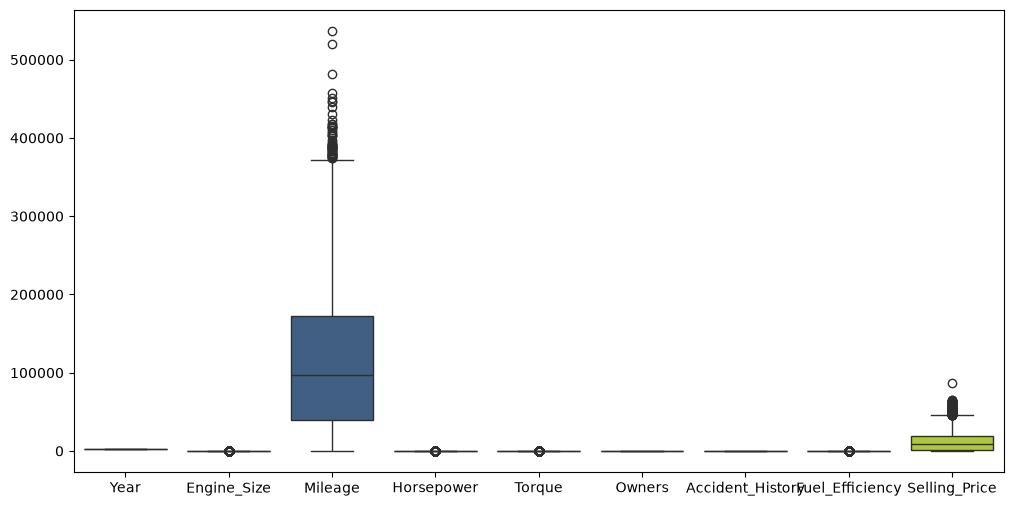

In [68]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df , palette='viridis')
plt.show()


**Insight**: Visualisasi boxplot menunjukkan perbedaan skala antarfitur yang sangat signifikan, di mana rentang nilai Mileage dan Selling_Price mendominasi grafik serta memiliki banyak outlier, sehingga dataset memerlukan proses normalisasi atau scaling sebelum dimodelkan.

### 3.4 Visualisasi Distribusi Harga

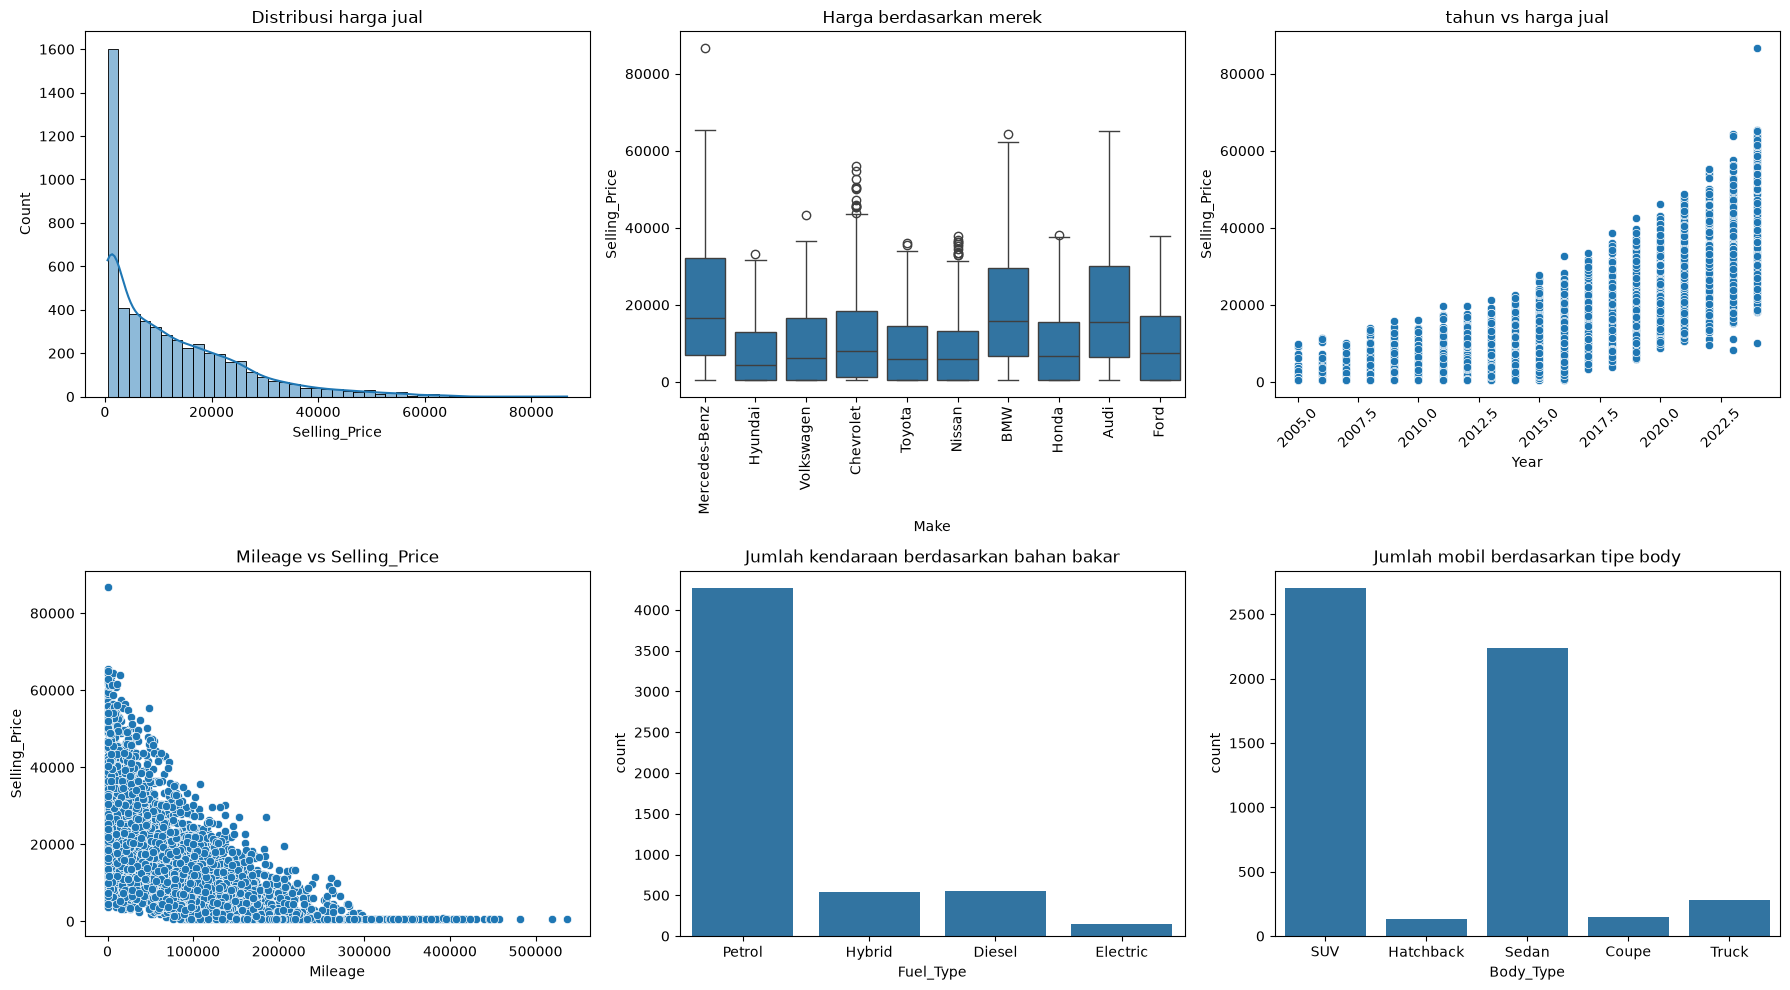

In [69]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.histplot(df["Selling_Price"], kde=True, ax=axes[0,0])
axes[0,0].set_title('Distribusi harga jual')

sns.boxplot(data=df, x="Make", y="Selling_Price", ax=axes[0,1])
axes[0,1].set_title('Harga berdasarkan merek')
axes[0,1].tick_params(axis="x", rotation=90)

sns.scatterplot(data=df, x="Year", y="Selling_Price", ax=axes[0,2])
axes[0,2].set_title('tahun vs harga jual')
axes[0,2].tick_params(axis="x", rotation=45)

sns.scatterplot(data=df, x="Mileage", y="Selling_Price", ax=axes[1,0])
axes[1,0].set_title('Mileage vs Selling_Price')

sns.countplot(data=df, x="Fuel_Type", ax=axes[1,1])
axes[1,1].set_title('Jumlah kendaraan berdasarkan bahan bakar')

sns.countplot(data=df, x="Body_Type", ax=axes[1,2])
axes[1,2].set_title('Jumlah mobil berdasarkan tipe body')

plt.tight_layout()
plt.show()

**Insight**: Distribusi harga jual menunjukkan kemencengan kanan dengan mayoritas kendaraan berada di bawah $20.000, di mana nilai jual dipengaruhi secara positif oleh keluaran terbaru dan kategori merek premium, dipengaruhi secara negatif oleh tingginya jarak tempuh (mileage), serta didominasi secara signifikan oleh kendaraan berbahan bakar Petrol dan tipe bodi SUV maupun Sedan.

### 3.5 Analisis Korelasi Metode Pearson, Spearman, dan Kendall

In [70]:
var_list = ['Year', 'Mileage', 'Owners', 'Selling_Price']

korelasi_list = []

for i in range(len(var_list)):
  for j in range(i + 1, len(var_list)):
    var1 = var_list[i]
    var2 = var_list[j]
    clean_df = df[[var1, var2]].dropna()
    pearson = clean_df[var1].corr(clean_df[var2], method='pearson')
    spearman = clean_df[var1].corr(clean_df[var2], method='spearman')
    kendall = clean_df[var1].corr(clean_df[var2], method='kendall')
    
    korelasi_list.append({
      'pasangan variabel': f'{var1} vs {var2}',
      'korelasi pearson': pearson,
      'korelasi spearman': spearman,
      'korelasi kendal': kendall
    })
    
pd.DataFrame(korelasi_list)

,pasangan variabel,korelasi pearson,korelasi spearman,korelasi kendal
0,Year vs Mileage,-0.754184,-0.784479,-0.621598
1,Year vs Owners,-0.830702,-0.842331,-0.708532
2,Year vs Selling_Price,0.804933,0.877923,0.705426
3,Mileage vs Owners,0.628654,0.668095,0.522810
4,Mileage vs Selling_Price,-0.682883,-0.833656,-0.641746
5,Owners vs Selling_Price,-0.669046,-0.755497,-0.607667


### 3.6 Visualisasi Heatmap pada kolom numerik

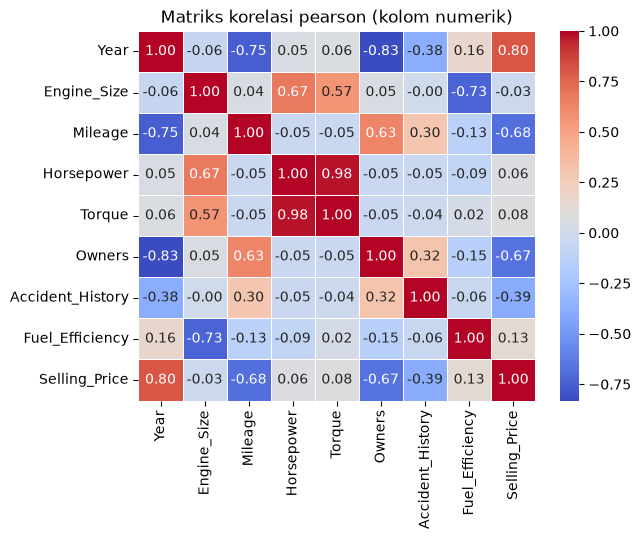

In [71]:
numeric = df.select_dtypes(include=[np.number])

corr_matrix = numeric.corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks korelasi pearson (kolom numerik)')
plt.show()

**Insight**: Matriks korelasi Pearson menunjukkan korelasi positif yang sangat kuat antara Horsepower dan Torque (0,98) yang berpotensi menyebabkan multikolinearitas, sementara faktor penentu utama harga jual (Selling_Price) adalah Year dengan hubungan positif kuat (0,80) serta Mileage (-0,68) dan Owners (-0,67) dengan hubungan negatif kuat.

### 3.7 Visuailisasi Heatmap Pada Keseluruhan Kolom

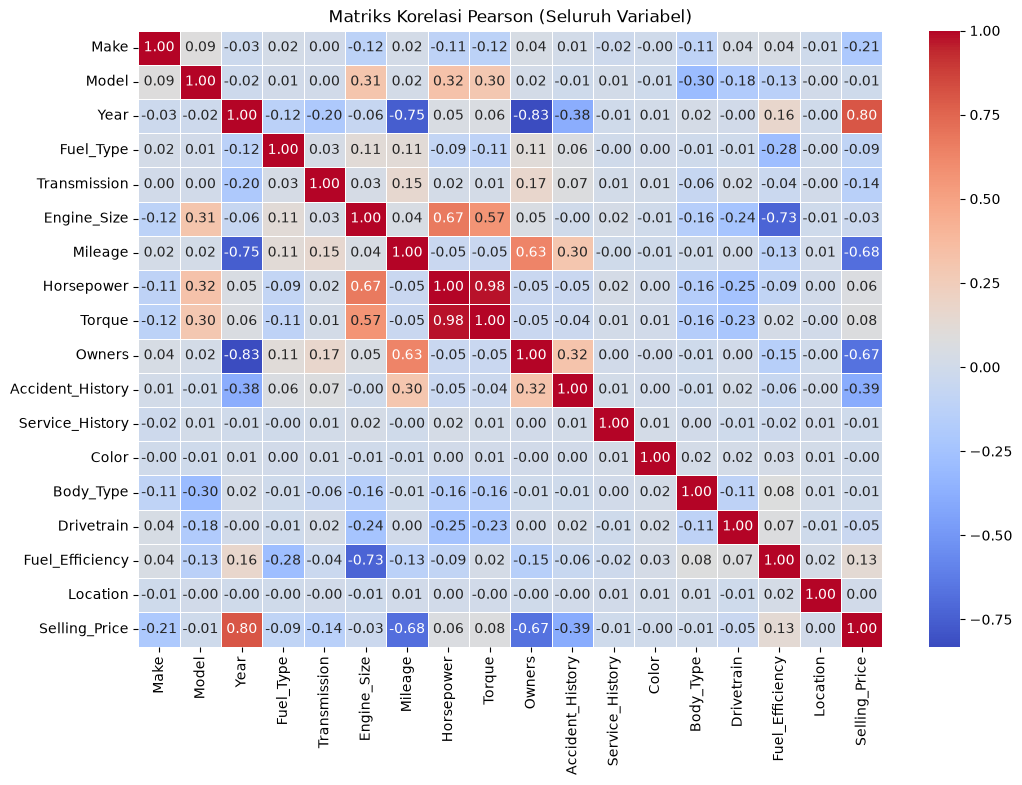

In [72]:
df_encoded = df.copy()

for col in df_encoded.select_dtypes(include=['object', 'string']).columns:
  df_encoded[col] = df_encoded[col].astype('category').cat.codes
  
corr_all = df_encoded.corr(method='pearson')

plt.figure(figsize=(12, 8))
sns.heatmap(corr_all, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Pearson (Seluruh Variabel)')
plt.show()

**Insight**: Matriks korelasi Pearson seluruh variabel menunjukkan bahwa variabel kategorikal yang telah di-encode (seperti Service_History, Color, dan Location) memiliki korelasi mendekati nol (-0.01 hingga 0.01) terhadap Selling_Price, sementara faktor utama penentu harga tetap didominasi oleh Year (0,80), Mileage (-0,68), dan Owners (-0,67).   

---

## 4. Data Preprocessing

### 4.1 Memeriksa Missing Value dan Duplikasi Data

In [73]:
print("--- Jumlah Missing Value per Kolom ---")
print(df.isnull().sum())
print("\n--- Jumlah Duplikasi Data ---")
print(df.duplicated().sum())

--- Jumlah Missing Value per Kolom ---
Make                  0
Model                 0
Year                  0
Fuel_Type             0
Transmission        827
Engine_Size         844
Mileage               0
Horsepower          800
Torque              799
Owners                0
Accident_History    812
Service_History     855
Color               803
Body_Type             0
Drivetrain            0
Fuel_Efficiency     794
Location            782
Selling_Price         0
dtype: int64

--- Jumlah Duplikasi Data ---
0


### 4.2 Menghapus Kolom Make, Model, dan Location & Mengimputasi Kolom yang Memiliki Missing Value

In [74]:
df = df.drop(columns=['Make', 'Model', 'Location'])

kolom_numerik = ['Engine_Size', 'Horsepower', 'Torque', 'Fuel_Efficiency', 'Accident_History']
for kol in kolom_numerik:
    df[kol] = pd.to_numeric(df[kol], errors='coerce')

df['Transmission'] = df['Transmission'].fillna(df['Transmission'].mode()[0])
df['Engine_Size'] = df['Engine_Size'].fillna(df['Engine_Size'].median())
df['Horsepower'] = df['Horsepower'].fillna(df['Horsepower'].median())
df['Torque'] = df['Torque'].fillna(df['Torque'].median())
df['Accident_History'] = df['Accident_History'].fillna(0) 
df['Service_History'] = df['Service_History'].fillna('No Service')
df['Color'] = df['Color'].fillna(df['Color'].mode()[0])
df['Fuel_Efficiency'] = df['Fuel_Efficiency'].fillna(df['Fuel_Efficiency'].median())

print("Total Missing Value setelah imputasi:", df.isnull().sum().sum())

Total Missing Value setelah imputasi: 0


### 4.3 Mengubah Teks Kategori Menjadi Angka Unik Serta Memisahkan Fitur Kategorikal pada Kolom Fuel_Type, Body_Type, dan Drivetrain

In [75]:
df['Transmission'] = pd.factorize(df['Transmission'])[0]
df['Service_History'] = pd.factorize(df['Service_History'])[0]
df['Color'] = pd.factorize(df['Color'])[0]

df = pd.get_dummies(df, columns=['Fuel_Type', 'Body_Type', 'Drivetrain'], drop_first=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 5500 non-null   int64  
 1   Transmission         5500 non-null   int64  
 2   Engine_Size          5500 non-null   float64
 3   Mileage              5500 non-null   int64  
 4   Horsepower           5500 non-null   float64
 5   Torque               5500 non-null   float64
 6   Owners               5500 non-null   int64  
 7   Accident_History     5500 non-null   float64
 8   Service_History      5500 non-null   int64  
 9   Color                5500 non-null   int64  
 10  Fuel_Efficiency      5500 non-null   float64
 11  Selling_Price        5500 non-null   int64  
 12  Fuel_Type_Electric   5500 non-null   bool   
 13  Fuel_Type_Hybrid     5500 non-null   bool   
 14  Fuel_Type_Petrol     5500 non-null   bool   
 15  Body_Type_Hatchback  5500 non-null   bool   
 16 

### 4.4 Membuat Label Target Baru

In [76]:
conditions = [
    df['Selling_Price'] <= 5000,
    (df['Selling_Price'] > 5000) & (df['Selling_Price'] <= 20000),
    df['Selling_Price'] > 20000
]

choices = ['Low', 'Medium', 'High']

df['Price_Category'] = np.select(conditions, choices, default='')

print("--- Menampilkan 5 Data Teratas ---\n", df[['Selling_Price', 'Price_Category']].head())
print("\n --- Jumlah Frekuensi ---\n", df['Price_Category'].value_counts())

--- Menampilkan 5 Data Teratas ---
    Selling_Price Price_Category
0          64140           High
1            500            Low
2          16429         Medium
3           2199            Low
4          21792           High

 --- Jumlah Frekuensi ---
 Price_Category
Medium    2125
Low       2091
High      1284
Name: count, dtype: int64


### 4.5 Mendeteksi dan Menangani Outlier (IQR dan Z-Score)

In [77]:
Q1 = df['Selling_Price'].quantile(0.25)
Q3 = df['Selling_Price'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier_awal = ((df['Selling_Price'] < batas_bawah) | (df['Selling_Price'] > batas_atas)).sum()
df['Selling_Price'] = np.clip(df['Selling_Price'], batas_bawah, batas_atas)
outlier_akhir = ((df['Selling_Price'] < batas_bawah) | (df['Selling_Price'] > batas_atas)).sum()

print(f"Outlier Awal: {outlier_awal} -> Sisa Outlier: {outlier_akhir}")


Outlier Awal: 144 -> Sisa Outlier: 0


### 4.6 Feature Scaling Menggunakan Standardization

In [78]:
features = ['Year', 'Engine_Size', 'Mileage', 'Horsepower', 'Torque', 'Owners', 'Fuel_Efficiency']

df[features] = df[features].fillna(df[features].median())

mean = df[features].mean()
std = df[features].std()
df[features] = (df[features] - mean) / std

print(df[features].describe())

               Year   Engine_Size       Mileage    Horsepower        Torque  \
count  5.500000e+03  5.500000e+03  5.500000e+03  5.500000e+03  5.500000e+03   
mean   1.476249e-14  3.533335e-16  1.162706e-17  2.596711e-16  1.408167e-16   
std    1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00   
min   -1.639796e+00 -3.145301e+00 -1.245709e+00 -1.929480e+00 -2.103160e+00   
25%   -9.489191e-01 -4.414429e-01 -8.210140e-01 -6.121931e-01 -5.983796e-01   
50%   -8.532327e-02 -5.517743e-02 -1.916306e-01 -1.860121e-01 -1.793269e-01   
75%    9.509918e-01  4.598432e-01  6.338851e-01  5.113748e-01  4.683001e-01   
max    1.641868e+00  4.193742e+00  4.596194e+00  4.598837e+00  4.868354e+00   

             Owners  Fuel_Efficiency  
count  5.500000e+03     5.500000e+03  
mean   6.911643e-17    -3.552714e-17  
std    1.000000e+00     1.000000e+00  
min   -1.143730e+00    -1.707704e+00  
25%   -1.143730e+00    -4.196857e-01  
50%   -3.624938e-01    -1.334595e-01  
75%    4.187428

### 4.7 Membagi Data Uji dan Data Latih (80%:20%)

In [79]:
X = df.drop(columns=['Selling_Price', 'Price_Category'])
y = df['Selling_Price']

print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk Y : {len(y)} label")

np.random.seed(43)
index = np.random.permutation(len(X))
batas = int(0.8 * len(X))

X_train = X.iloc[index[:batas]]
X_test = X.iloc[index[batas:]]
y_train = y.iloc[index[:batas]]
y_test = y.iloc[index[batas:]]

print(f"Data Latih  : {len(X_train)} baris (80%)")
print(f"Data Uji    : {len(X_test)} baris (20%)")

Bentuk X : 5500 baris, 21 kolom
Bentuk Y : 5500 label
Data Latih  : 4400 baris (80%)
Data Uji    : 1100 baris (20%)


---

## 5. Modelling Multiple Linear Regression

### 5.1 Menambahkan Kolom Intercept

In [80]:
def tambah_kolom_bias(x):
    return np.c_[np.ones(x.shape[0]), x].astype(float)

X_train_b = tambah_kolom_bias(X_train)
X_test_b = tambah_kolom_bias(X_test)

y_train = pd.to_numeric(y_train, errors='coerce')
y_test = pd.to_numeric(y_test, errors='coerce')

### 5.2 Melakukan Pelatihan Model Menggunakan Normal Equation (OLS)

In [81]:
beta = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

print("--- Hasil Pelatihan Model Multiple Linear Regression ---")
print(f"Intercept (Beta 0)      : {beta[0]:,.2f} USD")
print("-" * 50)

for index, koefisien in enumerate(beta[1:], start=1):
    print(f"Koefisien Fitur ke-{index}  : {koefisien:,.2f}")

--- Hasil Pelatihan Model Multiple Linear Regression ---
Intercept (Beta 0)      : 9,036.58 USD
--------------------------------------------------
Koefisien Fitur ke-1  : 8,058.77
Koefisien Fitur ke-2  : 1,572.49
Koefisien Fitur ke-3  : -153.67
Koefisien Fitur ke-4  : -2,112.06
Koefisien Fitur ke-5  : -284.64
Koefisien Fitur ke-6  : 318.74
Koefisien Fitur ke-7  : -119.98
Koefisien Fitur ke-8  : -1,916.75
Koefisien Fitur ke-9  : 536.41
Koefisien Fitur ke-10  : -7.33
Koefisien Fitur ke-11  : 209.94
Koefisien Fitur ke-12  : -1,850.39
Koefisien Fitur ke-13  : -89.95
Koefisien Fitur ke-14  : 223.71
Koefisien Fitur ke-15  : -1,606.74
Koefisien Fitur ke-16  : 4,724.55
Koefisien Fitur ke-17  : 2,371.32
Koefisien Fitur ke-18  : 2,749.06
Koefisien Fitur ke-19  : -326.44
Koefisien Fitur ke-20  : -660.43
Koefisien Fitur ke-21  : -471.52


### 5.3 Melakukan Prediksi pada Data Latih dan Data Uji & Menampilkan Tabel Perbandingan

In [82]:
y_pred_train = X_train_b @ beta
y_pred_test = X_test_b @ beta

tabel_hasil_prediksi = pd.DataFrame({'Harga Aktual (USD)': y_test.values[:5], 'Harga Prediksi (USD)': y_pred_test[:5]
})

print("\n--- Contoh 5 Prediksi Harga Mobil Bekas pada Data Uji ---")
print(tabel_hasil_prediksi.to_string(index=False, formatters={'Harga Aktual (USD)': '{:,.2f}'.format, 'Harga Prediksi (USD)': '{:,.2f}'.format
}))


--- Contoh 5 Prediksi Harga Mobil Bekas pada Data Uji ---
Harga Aktual (USD) Harga Prediksi (USD)
         20,357.00            18,877.96
         15,210.00            21,387.64
         26,219.00            27,629.79
         30,397.00            22,052.81
         45,786.62            27,710.80


---

## 6. Evaluation

### 6.1 Melakukan Evaluasi Menggunakan Matriks Regresi

In [83]:
r2 = 1 - (np.sum((y_test - y_pred_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))
mse = np.mean((y_test - y_pred_test) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_test - y_pred_test))

print("--- Hasil Evaluasi Model ---")
print(f"R-Squared   : {r2:.4f}")
print(f"MSE         : {mse:,.2f}")
print(f"RMSE        : {rmse:,.2f} USD")
print(f"MAE         : {mae:,.2f} USD")

--- Hasil Evaluasi Model ---
R-Squared   : 0.7089
MSE         : 44,206,775.74
RMSE        : 6,648.82 USD
MAE         : 5,194.47 USD


### 6.2 Menghitung Nilai Matriks Evaluasi dengan Membandingkan Nilai Aktual dan Nilai Prediksi pada Data Latih dan Data Uji

In [84]:
r2_train = 1 - (np.sum((y_train - y_pred_train) ** 2) / np.sum((y_train - np.mean(y_train)) ** 2))
mse_train = np.mean((y_train - y_pred_train) ** 2)
rmse_train = np.sqrt(mse_train)
mae_train = np.mean(np.abs(y_train - y_pred_train))

r2_test = 1 - (np.sum((y_test - y_pred_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))
mse_test = np.mean((y_test - y_pred_test) ** 2)
rmse_test = np.sqrt(mse_test)
mae_test = np.mean(np.abs(y_test - y_pred_test))

tabel_evaluasi = pd.DataFrame({
    'Metrik Evaluasi': ['R-Squared (R2)', 'MSE', 'RMSE (USD)', 'MAE (USD)'],
    'Data Latih': [r2_train, mse_train, rmse_train, mae_train],
    'Data Uji': [r2_test, mse_test, rmse_test, mae_test]
})

print("--- Perbandingan Evaluasi Model ---")
print(tabel_evaluasi.to_string(index=False, formatters={
    'Data Latih': lambda x: f"{x:,.4f}" if x < 1 else f"{x:,.2f}",
    'Data Uji': lambda x: f"{x:,.4f}" if x < 1 else f"{x:,.2f}"
}))

--- Perbandingan Evaluasi Model ---
Metrik Evaluasi    Data Latih      Data Uji
 R-Squared (R2)        0.7116        0.7089
            MSE 41,439,148.40 44,206,775.74
     RMSE (USD)      6,437.32      6,648.82
      MAE (USD)      5,060.55      5,194.47


### 6.3 Visualisasi Grafik Prediksi (Scatter Plot)

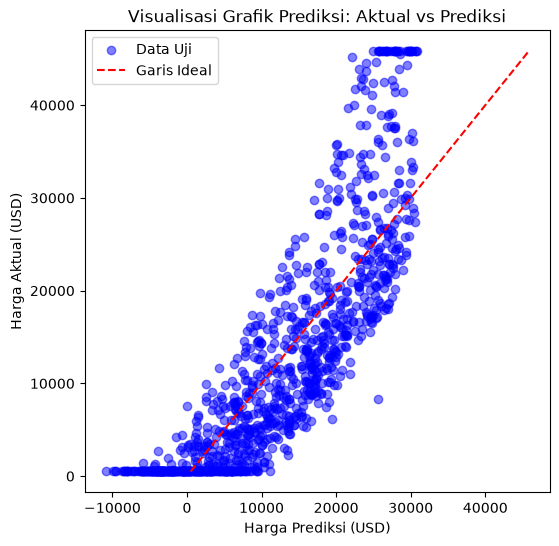

In [85]:
plt.figure(figsize=(6, 6))
plt.scatter(y_pred_test, y_test, color='blue', alpha=0.5, label='Data Uji')

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', label='Garis Ideal')

plt.xlabel('Harga Prediksi (USD)')
plt.ylabel('Harga Aktual (USD)')
plt.title('Visualisasi Grafik Prediksi: Aktual vs Prediksi')
plt.legend()

plt.show()

---
## 7. GUI

Untuk menjembatani model machine learning dengan pengguna akhir (end-user), dibuat antarmuka grafis untuk memudahkan pengguna memasukkan informasi kendaraan tanpa harus berinteraksi langsung dengan kode program. Melalui GUI ini, data seperti merek, tahun, jarak tempuh, jumlah pemilik, dan riwayat kecelakaan diproses oleh model regresi linear untuk menghasilkan estimasi harga mobil secara otomatis.

In [86]:
df = pd.read_csv("automobile_dataset.csv")
df.columns = df.columns.str.strip()
df["Make"] = df["Make"].str.strip()

MEREK_MAP = {
    merek: nomor
    for nomor, merek in enumerate(df["Make"].unique(), start=1)
}

YEAR_BASE = 2000

data = df[[
    "Make", "Year", "Mileage",
    "Owners", "Accident_History", "Selling_Price"
]].copy()

data["Make"] = data["Make"].map(MEREK_MAP)

for kolom in data.columns:
    if kolom != "Make":
        data[kolom] = pd.to_numeric(data[kolom], errors="coerce")

data["Year"] -= YEAR_BASE
data = data.dropna()

X = data[[
    "Make", "Year", "Mileage",
    "Owners", "Accident_History"
]].values

y = data["Selling_Price"].values

X = np.column_stack((np.ones(len(X)), X))
bobot = np.linalg.pinv(X) @ y

INTERCEPT = bobot[0]
WEIGHTS = bobot[1:]


def predict_price():
    try:
        merek = entryMerek.get()
        tahun = int(entryTahun.get())
        mileage = float(entryTempuh.get())
        owners = int(segowners.get())
        accident = int(segRiwayat.get())

        if merek not in MEREK_MAP:
            raise ValueError("Merek tidak valid")

        if mileage < 0:
            raise ValueError("Jarak tempuh tidak valid")

        fitur = np.array([
            1,
            MEREK_MAP[merek],
            tahun - YEAR_BASE,
            mileage,
            owners,
            accident
        ])

        harga = INTERCEPT + np.dot(fitur[1:], WEIGHTS)
        harga = max(0, harga)

        lbl_hasil.configure(
            text=f"Estimasi Harga: $ {harga:,.0f}",
            text_color="#2e7d32"
        )

    except ValueError as error:
        lbl_hasil.configure(
            text=f"Error: {error}",
            text_color="#d32f2f"
        )

In [88]:
from customtkinter import *

app = CTk()
app.title("prediksi harga jual mobil bekas")

lebar = 500
tinggi = 700
screen_width = app.winfo_screenwidth()
screen_height = app.winfo_screenheight()
x = int((screen_width / 2) - (lebar / 2) - 90)
y = int((screen_height / 2) - (tinggi / 2) - 100)
app.geometry(f"{lebar}x{tinggi}+{x}+{y}")

set_appearance_mode("light")
app.configure(fg_color="#e8e8e8")

judul = CTkLabel(master=app, text="Prediksi Harga Jual Mobil Bekas", font=("Arial", 24, "bold"), fg_color="transparent")
judul.pack(pady=20)

deskripsi = CTkLabel(master=app, text="Multiple Linear Regression", font=("Arial", 12), fg_color="transparent")
deskripsi.pack()

form_frame = CTkFrame(master=app, fg_color="#f1f1f1", corner_radius=12)
form_frame.pack(pady=(20, 0), padx=20, fill="both", expand=True)

lblMerek = CTkLabel(master=form_frame, text="Merek Mobil", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblMerek.pack(pady=(10, 0), padx=20, anchor="w")
entryMerek = CTkOptionMenu(master=form_frame, values=["Toyota", "Honda", "Hyundai", "Nissan", "Volkswagen", "BMW", "Mercedes-Benz", "Audi", "Chevrolet", "Ford"], fg_color="#36719F")
entryMerek.pack(pady=(0, 10), padx=20, fill="x")

lblTahun = CTkLabel(master=form_frame, text="Tahun Pembuatan", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblTahun.pack(pady=(10, 0), padx=20, anchor="w")
entryTahun = CTkEntry(master=form_frame, placeholder_text="e.g. 2020", corner_radius=8, height=32)
entryTahun.pack(pady=(0, 10), padx=20, fill="both")

lblTempuh = CTkLabel(master=form_frame, text="Jarak Tempuh", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblTempuh.pack(pady=(10, 0), padx=20, anchor="w")
entryTempuh = CTkEntry(master=form_frame, placeholder_text="e.g. 50000", corner_radius=8, height=32)
entryTempuh.pack(pady=(0, 10), padx=20, fill="both")

lblowners = CTkLabel(master=form_frame, text="Jumlah Pemilik Sebelumnya", font=("Arial", 13, "bold"))
lblowners.pack(anchor="w", padx=20, pady=(5, 2))
segowners = CTkSegmentedButton(master=form_frame, values=["1", "2", "3", "4", "5"])
segowners.set("1")
segowners.pack(fill="x", padx=20, pady=(0, 10))

lblRiwayat = CTkLabel(master=form_frame, text="Riwayat Kecelakaan", font=("Arial", 13, "bold"))
lblRiwayat.pack(anchor="w", padx=20, pady=(5, 2))
segRiwayat = CTkSegmentedButton(master=form_frame, values=["0", "1"])
segRiwayat.set("0")
segRiwayat.pack(fill="x", padx=20, pady=(0, 10))

btn_prediksi = CTkButton(master=app, text="Hitung Prediksi Harga", font=("Arial", 14, "bold"), fg_color="#36719F", height=40, command=predict_price)
btn_prediksi.pack(fill="x", padx=20, pady=10)

lbl_hasil = CTkLabel(
    master=app,
    text="Estimasi Harga: $ -",
    font=("Arial", 14, "bold"),
    fg_color="transparent",
)
lbl_hasil.pack(pady=(0, 15))

app.mainloop()

---

## 8. Conclusion

### 8.1 Kesimpulan Analisis dan Permodelan

Berdasarkan seluruh tahapan analisis data, *preprocessing*, pemodelan, hingga evaluasi yang telah dilakukan, dapat ditarik beberapa kesimpulan utama sebagai berikut:

1. Dataset awal terdiri dari **5.500 baris dan 18 kolom**. Pemeriksaan awal menunjukkan bahwa dataset bebas dari duplikasi data, namun ditemukan sejumlah nilai kosong (*missing value*) pada beberapa kolom spesifikasi yang berhasil diimputasi menggunakan metode median dan modus agar kualitas data tetap terjaga sebelum masuk ke tahap pemodelan. [Lihat Pemeriksaan Data Awal](#41-memeriksa-missing-value-dan-duplikasi-data)

2. Berdasarkan tahapan *preprocessing* dan *feature engineering*, kolom yang tidak relevan telah dihapus, teks kategori dikonversi menjadi angka dan dipisah menggunakan *one-hot encoding*, label target baru (`Price_Category`) dibentuk, pencilan (*outlier*) ditangani menggunakan metode IQR, serta fitur numerik distandarisasi sebelum dataset dibagi menjadi **4.400 data latih (80%)** dan **1.100 data uji (20%)**. [Lihat Transformasi dan Pembagian Data](#43-mengubah-teks-kategori-menjadi-angka-unik-serta-memisahkan-fitur-kategorikal-pada-kolom-fuel_type-body_type-dan-drivetrain)

3. Pengujian model menggunakan algoritma **Multiple Linear Regression (OLS)** yang dilatih melalui metode *Normal Equation* berhasil menghasilkan parameter intersep dan koefisien bobot yang optimal. Berdasarkan hasil evaluasi, model terbukti mampu memprediksi harga mobil bekas secara akurat dan konsisten dengan performa yang baik antara data latih dan data uji tanpa adanya indikasi *overfitting*. [Lihat Pelatihan dan Evaluasi Model](#52-melakukan-pelatihan-model-menggunakan-normal-equation-ols)